# SpaceX Falcon 9 – Machine Learning Prediction
Predict whether the first stage lands using Logistic Regression, SVM, Decision Tree and KNN tuned with GridSearchCV.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(y, y_predict, title='Confusion Matrix'):
    cm = confusion_matrix(y, y_predict)
    ax = plt.subplot()
    sns.heatmap(cm, annot=True, ax=ax, fmt='d', cmap='Blues')
    ax.set_xlabel('Predicted labels'); ax.set_ylabel('True labels'); ax.set_title(title)
    ax.xaxis.set_ticklabels(['did not land', 'land']); ax.yaxis.set_ticklabels(['did not land', 'landed'])
    plt.show()

In [2]:
data = pd.read_csv("data/dataset_part_2.csv")
X = pd.read_csv("data/dataset_part_3.csv")
X.shape

(90, 80)

## Task 1: Create the target array Y from the Class column

In [3]:
Y = data['Class'].to_numpy()

## Task 2: Standardize the data

In [4]:
transform = preprocessing.StandardScaler()
X = transform.fit_transform(X)

## Task 3: Split into training and test data

In [5]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
Y_test.shape

(18,)

## Task 4–5: Logistic Regression

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logi

best parameters: {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}
CV accuracy: 0.8214285714285714
test accuracy: 0.8333333333333334


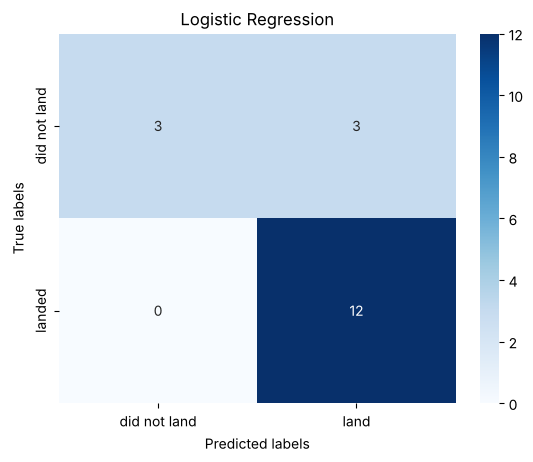

In [6]:
parameters = {'C': [0.01, 0.1, 1], 'penalty': ['l2'], 'solver': ['lbfgs']}
logreg_cv = GridSearchCV(LogisticRegression(max_iter=1000), parameters, cv=10).fit(X_train, Y_train)
print("best parameters:", logreg_cv.best_params_)
print("CV accuracy:", logreg_cv.best_score_)
print("test accuracy:", logreg_cv.score(X_test, Y_test))
plot_confusion_matrix(Y_test, logreg_cv.predict(X_test), 'Logistic Regression')

## Task 6–7: Support Vector Machine

best parameters: {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}
CV accuracy: 0.8482142857142858
test accuracy: 0.8333333333333334


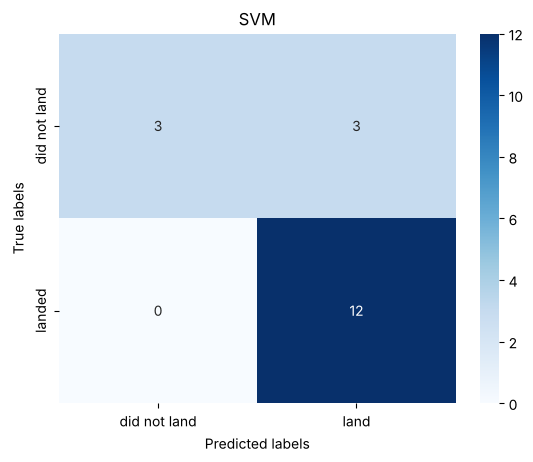

In [7]:
parameters = {'kernel': ('linear', 'rbf', 'poly', 'sigmoid'), 'C': np.logspace(-3, 3, 5), 'gamma': np.logspace(-3, 3, 5)}
svm_cv = GridSearchCV(SVC(), parameters, cv=10).fit(X_train, Y_train)
print("best parameters:", svm_cv.best_params_)
print("CV accuracy:", svm_cv.best_score_)
print("test accuracy:", svm_cv.score(X_test, Y_test))
plot_confusion_matrix(Y_test, svm_cv.predict(X_test), 'SVM')

## Task 8–9: Decision Tree

best parameters: {'criterion': 'gini', 'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 2, 'splitter': 'best'}
CV accuracy: 0.8339285714285716
test accuracy: 0.9444444444444444


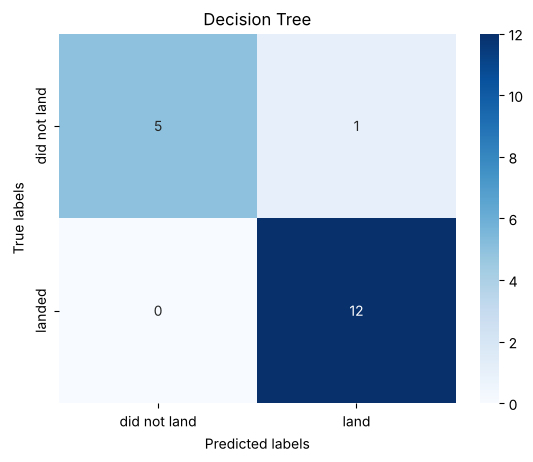

In [8]:
parameters = {'criterion': ['gini', 'entropy'], 'splitter': ['best', 'random'],
    'max_depth': [2 * n for n in range(1, 10)], 'max_features': ['sqrt'],
    'min_samples_leaf': [1, 2, 4], 'min_samples_split': [2, 5, 10]}
tree_cv = GridSearchCV(DecisionTreeClassifier(random_state=0), parameters, cv=10).fit(X_train, Y_train)
print("best parameters:", tree_cv.best_params_)
print("CV accuracy:", tree_cv.best_score_)
print("test accuracy:", tree_cv.score(X_test, Y_test))
plot_confusion_matrix(Y_test, tree_cv.predict(X_test), 'Decision Tree')

## Task 10–11: K Nearest Neighbors

best parameters: {'algorithm': 'auto', 'n_neighbors': 6, 'p': 1}
CV accuracy: 0.8339285714285714
test accuracy: 0.8333333333333334


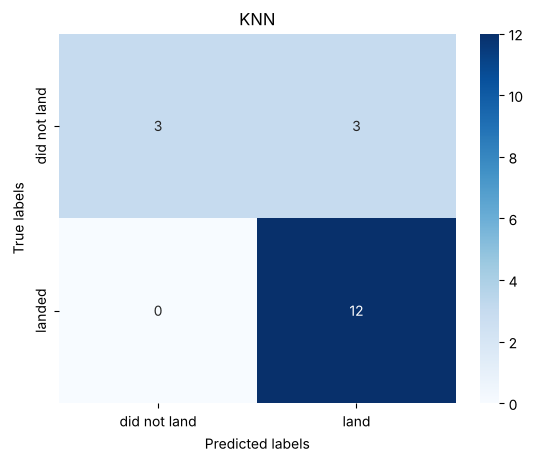

In [9]:
parameters = {'n_neighbors': list(range(1, 11)), 'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'], 'p': [1, 2]}
knn_cv = GridSearchCV(KNeighborsClassifier(), parameters, cv=10).fit(X_train, Y_train)
print("best parameters:", knn_cv.best_params_)
print("CV accuracy:", knn_cv.best_score_)
print("test accuracy:", knn_cv.score(X_test, Y_test))
plot_confusion_matrix(Y_test, knn_cv.predict(X_test), 'KNN')

## Task 12: Find the method that performs best

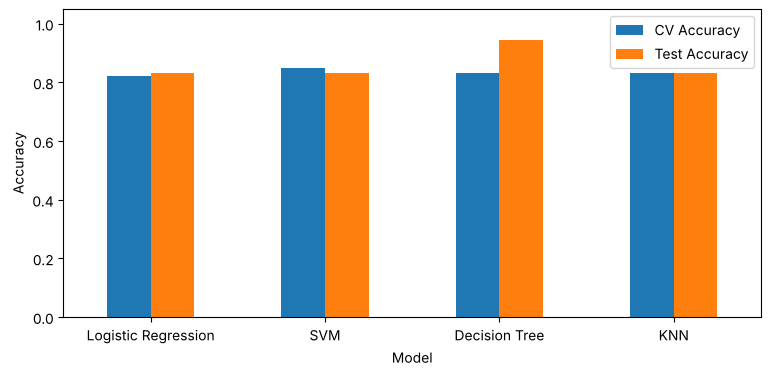

Best model: Decision Tree


,Model,CV Accuracy,Test Accuracy
0,Logistic Regression,0.8214,0.8333
1,SVM,0.8482,0.8333
2,Decision Tree,0.8339,0.9444
3,KNN,0.8339,0.8333


In [10]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'SVM', 'Decision Tree', 'KNN'],
    'CV Accuracy': [m.best_score_ for m in [logreg_cv, svm_cv, tree_cv, knn_cv]],
    'Test Accuracy': [m.score(X_test, Y_test) for m in [logreg_cv, svm_cv, tree_cv, knn_cv]],
}).round(4)
ax = results.set_index('Model')[['CV Accuracy', 'Test Accuracy']].plot(kind='bar', figsize=(9, 4), rot=0)
ax.set_ylim(0, 1.05); ax.set_ylabel('Accuracy'); plt.show()
best = results.sort_values(['Test Accuracy', 'CV Accuracy'], ascending=False).iloc[0]
print("Best model:", best['Model'])
results